# CSCI1409 Deep Learning — Week 4 SIS Mini-project 1
## FashionMNIST: train your first MLP and read its loss curves

**SIS mini-project 1:** 4 course points · **Defense:** in class, Week 4  
**Goal:** build a small neural network (MLP), train it twice — once with **SGD** and once with **Adam** — and plot how the **loss** changes on training and validation data.

You work in groups of 3. Apart from the dataset download, **all code in this notebook is written by your group.** The cells only contain `# TODO` comments with hints. Every student must be able to explain every line and every plot. Write short answers in the answer cells (2–3 sentences each is enough).

**Before class:** make sure `torch`, `torchvision`, and `matplotlib` are installed ([PyTorch setup guide](https://pytorch.org/get-started/locally/)). The first download of FashionMNIST needs internet. **A CPU is enough** — no GPU needed.

### AI-use rule for this lab (Level C — AI-Assisted)

You may use generative AI to get ideas, explain concepts, debug code, or get feedback. However, **your group must write the main solution yourselves** and **understand and check everything you submit**. At the defense you will explain your code and plots without AI help — "the AI wrote it" is not an answer.

Check AI explanations against the lectures and the PyTorch documentation. Plagiarism, copying another group's code, and invented results are not allowed under any circumstances. If you used an external source (tutorial, blog, docs), name it in your answers.

## 1. Dataset

FashionMNIST has 28×28 grayscale images of clothing in 10 classes (T-shirt, trouser, sneaker, …). The download code is given. We use only the **official training portion**; the official test set is not used today.

Key words:
- **Training set** — the images the model learns from (used to compute gradients).
- **Validation set** — images the model never learns from; we use them only to check how well it works on *new* data.

In [1]:
# PROVIDED: download/load the official training portion.
# ToTensor gives each image the shape [1, 28, 28] with pixel values in [0, 1].
from torchvision import datasets, transforms

DATA_ROOT = "./data"

full_training_data = datasets.FashionMNIST(
    root=DATA_ROOT,
    train=True,
    download=True,
    transform=transforms.ToTensor(),
)
print("Official training portion:", len(full_training_data), "images")
print("Classes:", full_training_data.classes)

Official training portion: 60000 images
Classes: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


In [2]:
# TODO: import what you need (torch, torch.nn, DataLoader, random_split, matplotlib, ...)
import torch
import torch.nn as nn
import torch.nn.functional as F
# TODO: fix a random seed (e.g. torch.manual_seed(42)) so your results are repeatable
torch.manual_seed(42)

In [14]:
# TODO: take a random subset of 6,000 images and split it into 5,000 train and 1,000 val
#       hint: torch.utils.data.random_split with a torch.Generator seeded by your seed
generator = torch.Generator().manual_seed(42)
subset, _ = torch.utils.data.random_split(full_training_data,[6000, 54000], generator = generator)
train, val = torch.utils.data.random_split(subset,[5000, 1000])
# TODO: print the number of train and val images
print(len(train))
print(len(val))

5000
1000


torch.Size([1, 28, 28])
8


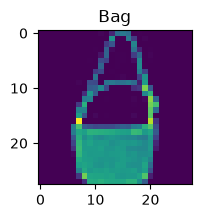

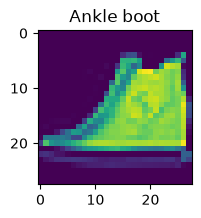

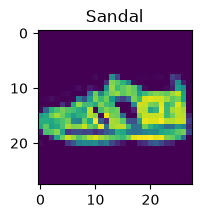

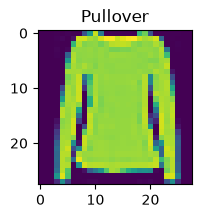

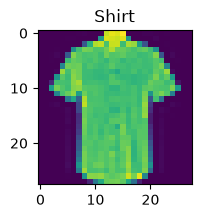

In [30]:
# TODO: print the shape and label of one training image
image, label = train[0]
print(image.shape)
print(label)
# TODO: show 5 training images with their class names (matplotlib)
import matplotlib.pyplot as plt
classes = full_training_data.classes
for i in range(5):
    image, label = train[i]
    plt.figure(figsize=(2,2))
    plt.imshow(image.squeeze())
    plt.title(classes[label])
    plt.show()

**Your answer — dataset**

- How many images are in train and in val?

in train = 5000

in val = 1000
- What does the shape `[1, 28, 28]` mean?

1 - channel 

28 - heigh and weigh
- Why must validation images never be used to update the model's weights?

because we use validation data for already trained model for take a test

_Write your answers here._

## 2. Build your model

Design a small **MLP** (multi-layer perceptron). Requirements:

- input: a batch of images of shape `[1, 28, 28]` → flatten to 784 numbers
- at least **one hidden layer** with a nonlinearity (e.g. ReLU)
- output: **10 numbers per image** (one score — a *logit* — per class)

A simple design is enough, e.g. `784 → 128 → 10`.

In [32]:
# TODO: define your MLP as an nn.Module (or nn.Sequential)
#       hint: nn.Flatten, nn.Linear, nn.ReLU
class Model(nn.Module):
    # Input Layer (4 features of flower) --> Hidden Layer 1 (numbers of neurons) -->
    # HL2 (numbers od neurons) --> output layer (3 classes of iris flower)
    def __init__(self):
        super().__init__()  # instantiate our nn.Module
        self.flatten = nn.Flatten()
        
        self.fc1 = nn.Linear(28 * 28, 128)
        self.fc2 = nn.Linear(128, 64)
        self.out = nn.Linear(64, 10)
        
        self.relu = nn.ReLU()
        
    def forward(self, x):
        x = self.flatten(x)
        
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))

        x = self.out(x)
        return x

In [35]:
# TODO: pass a small batch of images through the model and check the output shape is (batch_size, 10)
model = Model()

batch_size = 4

images = torch.stack([train[i][0] for i in range(batch_size)])

outputs = model(images)

print(outputs.shape)

assert outputs.shape == (batch_size, 10)


torch.Size([4, 10])


**Your answer — model**

- Write your architecture (layer sizes and activation).

first layer is input here we get (784,128) data, it means image by 28x28, and it goes like 128 output to next layer. Second layer (128,64), it means we got 128 features and we will process it to 64 output, after that output layer 64 feautures becomes 10 output because we have 10 class

- Why do we need a nonlinearity between the layers?

We use ReLU to add nonlinearity to the model. This allows the model to learn more complex patterns. Without ReLU, multiple linear layers would behave like one linear layer.

_Write your answers here._

## 3. Training setup

Use these **suggested settings** (you may change them, but write down what you used):

| Setting | Suggested value |
|---|---|
| Batch size | 64 |
| Epochs | 10 |
| SGD learning rate | 0.1 |
| Adam learning rate | 0.001 |

Keep the model, seed, batch size, and number of epochs **the same** for SGD and Adam — only the optimizer changes. That way the comparison is fair.

In [ ]:
# TODO: create a DataLoader for train (shuffle=True) and one for val (shuffle=False)
batch_size = 64

train_loader = torch.utils.data.DataLoader(
    train,
    batch_size=batch_size,
    shuffle=True
)

val_loader = torch.utils.data.DataLoader(
    val,
    batch_size=batch_size,
    shuffle=False
)
# TODO: choose a loss function for 10-class classification
criterion = nn.CrossEntropyLoss()

epochs = 10

optimizer = torch.optim.SGD(
    model.parameters(),
    lr = 0.1
)

**Your prediction (write it BEFORE training)**

- Which optimizer do you think will make the training loss go down faster: SGD or Adam? Why?



_Write your prediction here._

## 4. Training and evaluation code

Write two functions yourselves:

1. **`train_one_epoch`** — goes through all training batches once. For each batch:  
   (a) clear old gradients → (b) forward pass → (c) compute the loss → (d) backpropagate → (e) update the weights.  
   Use `model.train()`.
2. **`evaluate`** — returns the average loss and accuracy on a loader. Use `model.eval()` and `torch.no_grad()`, so **no gradients and no weight updates** happen here.

At the defense you must point to the lines (a)–(e) in your code.

In [40]:
# TODO: write train_one_epoch(model, loader, loss_fn, optimizer)
#       zero_grad -> forward -> loss -> backward -> step
def train_one_epoch(model, loader, loss_fn, optimizer):
    model.train()

    total_loss = 0

    for images, labels in loader:

        # (a) clear old gradients
        optimizer.zero_grad()

        # (b) forward pass
        outputs = model(images)

        # (c) compute loss
        loss = loss_fn(outputs, labels)

        # (d) backpropagation
        loss.backward()

        # (e) update weights
        optimizer.step()

        total_loss += loss.item()

    return total_loss / len(loader)

In [ ]:
# TODO: write evaluate(model, loader, loss_fn) that returns (average loss, accuracy)
def evaluate(model, loader, loss_fn):
    model.eval()

    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:

            # Forward pass
            outputs = model(images)

            # Loss
            loss = loss_fn(outputs, labels)
            total_loss += loss.item()

            # Predictions
            predictions = outputs.argmax(dim=1)

            # Count correct predictions
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    average_loss = total_loss / len(loader)
    accuracy = correct / total

    return average_loss, accuracy

In [42]:
# TODO: write run_experiment(optimizer_name, lr) that:
#       - resets the seed and builds a NEW model (so both runs start from the same weights)
#       - creates the optimizer: torch.optim.SGD or torch.optim.Adam
#       - for each epoch: train once, then evaluate on train and on val
#       - stores train loss and val loss for every epoch in two lists and returns them
#       - prints epoch number, train loss, val loss, val accuracy
def run_experiment(optimizer_name, lr):
    # 1. Reset seed
    torch.manual_seed(42)

    # 2. Create a NEW model
    model = Model()

    # 3. Choose optimizer
    if optimizer_name == "SGD":
        optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    elif optimizer_name == "Adam":
        optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    else:
        raise ValueError("Optimizer must be 'SGD' or 'Adam'")

    # 4. Lists for storing losses
    train_losses = []
    val_losses = []

    # 5. Training loop
    for epoch in range(10):

        # Train for one epoch
        train_one_epoch(model, train_loader, criterion, optimizer)

        # Evaluate on training data
        train_loss, train_accuracy = evaluate(
            model, train_loader, criterion
        )

        # Evaluate on validation data
        val_loss, val_accuracy = evaluate(
            model, val_loader, criterion
        )

        # Store losses
        train_losses.append(train_loss)
        val_losses.append(val_loss)

        # Print results
        print(
            f"Epoch {epoch + 1}: "
            f"train loss = {train_loss:.4f}, "
            f"val loss = {val_loss:.4f}, "
            f"val accuracy = {val_accuracy:.4f}"
        )

    return train_losses, val_losses

## 5. Run SGD and Adam

In [11]:
# TODO: run the experiment with SGD

In [12]:
# TODO: run the experiment with Adam

## 6. Plot the loss curves

This is the main result of the lab. A **loss curve** shows the loss (y-axis) after each epoch (x-axis).

In [13]:
# TODO: plot train loss and val loss vs epoch for SGD and for Adam
#       (e.g. two panels side by side, same y-axis range; add a title, axis labels, and a legend)
# TODO: print the final train loss, final val loss, and final val accuracy for both runs

**Your answer — curves**

- Which optimizer reduced the training loss faster? Give one epoch and the numbers.
- Was your prediction correct?
- Look at the gap between train loss and val loss. Is the model overfitting (val loss goes up while train loss keeps going down), underfitting (both stay high), or fitting well?
- The two optimizers used different learning rates. Why does that make the comparison less clear-cut?

_Write your answers here. A surprising result is fine if you explain it with your plots._

## 7. Group contribution statement (required)

For each member, write what they did (e.g. data split, model, training loop, plots, answers) and how the group used AI (what for, and how you checked it). Every member must still be able to explain the whole notebook.

| Student (full name) | Main contribution | How AI was used and checked |
|---|---|---|
|  |  |  |
|  |  |  |
|  |  |  |

## 8. Defense checklist and grading

**Submit this completed notebook** (or an HTML/PDF export with all cells and plots visible) before your defense. Each group has a short (~5 min) defense. Any member may be asked to:

- explain any line of your code — the split, the model, and the training steps (a)–(e)
- explain why `model.eval()` and `torch.no_grad()` are used in `evaluate`
- read your loss plots: which optimizer was faster, and is there overfitting?
- say what AI helped with and how you checked it

The Week 4 SIS mini-project is worth **4 points**:

| Criterion | Points |
|---|---|
| Working code written by the group: data split, MLP, training loop, and evaluation; both SGD and Adam runs complete | 1 |
| Clear loss plots: train and val loss vs epoch for both optimizers, with title, axis labels, and legend | 1 |
| Answers: correct, short explanations of the dataset, model, and curves, based on your own numbers | 1 |
| Individual oral explanation of the group's code and plots at the defense | 1 |
| **Total** | **4** |

**Optional (no extra points):** add dropout (`nn.Dropout(0.3)`) after the hidden layer, train with Adam again, and compare the new loss curves with your old Adam curves. Did the train/val gap change?